In [1]:
def clean():
    import gc
    import torch

    # Release cached GPU memory
    gc.collect()
    torch.cuda.empty_cache()

clean()

In [2]:
!nvidia-smi

Sun Nov 15 12:14:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 596.36                 Driver Version: 596.36         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX 3500 Ada Gene...  WDDM  |   00000000:01:00.0  On |                  Off |
| N/A   52C    P8              7W /   85W |   11889MiB /  12282MiB |     27%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# check environment
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA device count:", torch.cuda.device_count())

PyTorch version: 2.5.1+cu121
CUDA available: True
CUDA device count: 1


In [4]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Program using device: {device}")

Program using device: cuda


In [5]:
import os
from pathlib import Path

datapath = Path("../data/VOCdevkit").resolve()

datapath_org_train = datapath / "VOC2012"
datapath_org_test = datapath / "VOC2007"

datapath_img_train = datapath_org_train / "JPEGImages"
datapath_anno_train = datapath_org_train / "Annotations"

In [7]:
epochs_cont: int = 30
batch_size: int = 4
momentum: float = 0.9
weight_decay: float = 0.0005
lr_step_size: int = 5
lr_gamma: float = 0.5
print_freq: int = 50
num_workers: int = 0
lr_bb: float = 0.0005
lr_head: float = 0.005

In [8]:

import os
import xml.etree.ElementTree as ET

import torch
from PIL import Image
from torch.utils.data import Dataset

VOC_CLASSES = [
    "__background__",
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person",
    "pottedplant", "sheep", "sofa", "train", "tvmonitor"
]

CLASS_TO_IDX = {
    name: idx for idx, name in enumerate(VOC_CLASSES)
}


class PascalVOCDataset(Dataset):

    def __init__(self, root, transforms=None, split=None):
        self.root = root
        self.transforms = transforms

        self.image_dir = os.path.join(root, "JPEGImages")
        self.annotation_dir = os.path.join(root, "Annotations")

        if split is not None:
            self.image_dir = os.path.join(self.image_dir, split)
            self.annotation_dir = os.path.join(self.annotation_dir, split)

        self.image_ids = sorted([
            f[:-4] for f in os.listdir(self.image_dir)
            if f.endswith(".jpg")
            and os.path.exists(
                os.path.join(self.annotation_dir, f[:-4] + ".xml")
            )
        ])

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):

        image_id = self.image_ids[idx]

        image_path = os.path.join(
            self.image_dir, image_id + ".jpg"
        )

        annotation_path = os.path.join(
            self.annotation_dir, image_id + ".xml"
        )

        image = Image.open(image_path).convert("RGB")

        tree = ET.parse(annotation_path)
        root = tree.getroot()

        boxes = []
        labels = []
        iscrowd = []

        for obj in root.findall("object"):

            class_name = obj.find("name").text

            if class_name not in CLASS_TO_IDX:
                continue

            bbox = obj.find("bndbox")

            xmin = float(bbox.find("xmin").text) - 1
            ymin = float(bbox.find("ymin").text) - 1
            xmax = float(bbox.find("xmax").text) - 1
            ymax = float(bbox.find("ymax").text) - 1

            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(CLASS_TO_IDX[class_name])

            difficult = obj.find("difficult")
            iscrowd.append(
                int(difficult.text) if difficult is not None else 0
            )

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        width, height = image.size

        area = (
            (boxes[:, 2] - boxes[:, 0]) *
            (boxes[:, 3] - boxes[:, 1])
        )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx]),
            "area": area,
            "iscrowd": torch.as_tensor(
                iscrowd, dtype=torch.int64
            )
        }

        if self.transforms is not None:
            image, target = self.transforms(image, target)

        return image, target


In [9]:
import random
import torchvision.transforms.functional as F

def transform_train(image, target):
    image = F.to_tensor(image)

    if random.random() < 0.5:
        image = F.hflip(image)

        width = image.shape[2]
        boxes = target["boxes"].clone()
        boxes[:, [0, 2]] = width - boxes[:, [2, 0]]
        target["boxes"] = boxes

    return image, target


def transform_test(image, target):
    image = F.to_tensor(image)
    return image, target

In [10]:
dataset_train = PascalVOCDataset(
    root=datapath_org_train,
    transforms=transform_train
)

dataset_val = PascalVOCDataset(
    root=datapath_org_test,
    transforms=transform_test,
    split="val"
)

dataset_test = PascalVOCDataset(
    root=datapath_org_test,
    transforms=transform_test,
    split="test"
)

In [11]:
from torch.utils.data import DataLoader

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    dataset_train,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    collate_fn=collate_fn,
    pin_memory=True
)

val_loader = DataLoader(
    dataset_val,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    collate_fn=collate_fn,
    pin_memory=True
)

test_loader = DataLoader(
    dataset_test,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    collate_fn=collate_fn,
    pin_memory=True
)

In [12]:
print("Dataset length:", len(dataset_train))

for i in range(4):
    print("Loading image:", i, flush=True)
    image, target = dataset_train[i]
    print("Loaded:", image.shape, flush=True)

Dataset length: 17125
Loading image: 0
Loaded: torch.Size([3, 500, 486])
Loading image: 1
Loaded: torch.Size([3, 281, 500])
Loading image: 2
Loaded: torch.Size([3, 366, 500])
Loading image: 3
Loaded: torch.Size([3, 375, 500])


In [14]:
import torch
import torch.nn as nn
import torchvision

from torchvision.models import VGG16_Weights
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.models.detection.faster_rcnn import TwoMLPHead

class RoIPoolWrapper(nn.Module):
    def __init__(self, output_size=7, spatial_scale=1/16):
        super().__init__()

        self.pool = torchvision.ops.RoIPool(
            output_size=output_size,
            spatial_scale=spatial_scale
        )

    def forward(self, features, proposals, image_shapes):
        return self.pool(features["0"], proposals)

In [15]:
from torchvision.models.detection.faster_rcnn import (
    TwoMLPHead,
    FastRCNNPredictor
)
from torchvision.ops import MultiScaleRoIAlign

def load_faster_rcnn_v1_base_vgg(num_classes=21):
    vgg = torchvision.models.vgg16(
        weights=VGG16_Weights.IMAGENET1K_V1
    )

    backbone = nn.Sequential(
        *list(vgg.features.children())[:-1]
    )
    backbone.out_channels = 512

    for param in backbone.parameters():
        param.requires_grad = False

    anchor_generator = AnchorGenerator(
        sizes=((128, 256, 512),),
        aspect_ratios=((0.5, 1.0, 2.0),)
    )

    roi_pooler = MultiScaleRoIAlign(
    featmap_names=["0"],
    output_size=(7, 7),
    sampling_ratio=2
)

    # Two fully connected layers: 25088 -> 4096 -> 4096
    box_head = TwoMLPHead(
        in_channels=512 * 7 * 7,
        representation_size=4096
    )

    # Initialize FC6 and FC7 from pretrained VGG16
    with torch.no_grad():
        box_head.fc6.weight.copy_(vgg.classifier[0].weight)
        box_head.fc6.bias.copy_(vgg.classifier[0].bias)
        box_head.fc7.weight.copy_(vgg.classifier[3].weight)
        box_head.fc7.bias.copy_(vgg.classifier[3].bias)

    # IMPORTANT: Predictor must receive 4096 features
    box_predictor = FastRCNNPredictor(
        in_channels=4096,
        num_classes=num_classes
    )

    model = FasterRCNN(
        backbone=backbone,
        num_classes=None,
        rpn_anchor_generator=anchor_generator,
        box_roi_pool=roi_pooler,
        box_head=box_head,
        box_predictor=box_predictor,
        min_size=600,
        max_size=1000
    )

    return model

model_fasterrcnn_v1 = load_faster_rcnn_v1_base_vgg().to(device)

In [16]:
from torchinfo import summary

def helper_display_model_info(model, model_name="Faster R-CNN"):

    print(f"\n{'=' * 70}")
    print(f"MODEL SUMMARY: {model_name}")
    print(f"{'=' * 70}")

    # Architecture
    print(model)

    # Parameter summary
    summary(
        model,
        depth=3,
        col_names=["num_params", "trainable"],
        verbose=1
    )

    # Count parameters
    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    frozen_params = total_params - trainable_params

    print(f"\n{'-' * 70}")
    print(f"Total Parameters:     {total_params:,}")
    print(f"Trainable Parameters: {trainable_params:,}")
    print(f"Frozen Parameters:    {frozen_params:,}")
    print(f"{'-' * 70}")

helper_display_model_info(model_fasterrcnn_v1)


MODEL SUMMARY: Faster R-CNN
FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(600,), max_size=1000, mode='bilinear')
  )
  (backbone): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padd

In [17]:
def helper_check_trainable_params(model):

    components = {
        "Backbone": model.backbone,
        "RPN": model.rpn,
        "ROI Pooler": model.roi_heads.box_roi_pool,
        "ROI Box Head": model.roi_heads.box_head,
        "ROI Predictor": model.roi_heads.box_predictor
    }

    for name, module in components.items():
        params = list(module.parameters())

        total = sum(p.numel() for p in params)
        trainable = sum(
            p.numel() for p in params if p.requires_grad
        )

        print(
            f"{name:<18} "
            f"Total: {total:>12,} | "
            f"Trainable: {trainable:>12,} | "
            f"Frozen: {total - trainable:>12,}"
        )

helper_check_trainable_params(model_fasterrcnn_v1)

Backbone           Total:   14,714,688 | Trainable:            0 | Frozen:   14,714,688
RPN                Total:    2,382,893 | Trainable:    2,382,893 | Frozen:            0
ROI Pooler         Total:            0 | Trainable:            0 | Frozen:            0
ROI Box Head       Total:  119,545,856 | Trainable:  119,545,856 | Frozen:            0
ROI Predictor      Total:      430,185 | Trainable:      430,185 | Frozen:            0


In [18]:
class modelScheduler_StepLR():
    def __init__(self, optimizer, step_size=10, gamma=0.1):
        self.optimizer = optimizer
        self.step_size = step_size
        self.gamma = gamma
        self.scheduler = torch.optim.lr_scheduler.StepLR(self.optimizer, step_size=self.step_size, gamma=self.gamma)

    def scheduler_step(self):
        self.scheduler.step()

In [19]:
class modelOpt_SGD():
    def __init__(
        self,
        model,
        lr_bb=0.0001,
        lr_head=0.001,
        mm=0.9,
        weight_decay=0.001
    ):
        self.model = model
        self.lr_bb = lr_bb
        self.lr_head = lr_head
        self.mm = mm
        self.weight_decay = weight_decay

        # 1. Backbone parameters (VGG16)
        backbone_params = list(self.model.backbone.parameters())

        # 2. Detection head parameters (RPN + RoI Heads)
        head_params = (
            list(self.model.rpn.parameters()) +
            list(self.model.roi_heads.parameters())
        )

        # 3. SGD optimizer with separate learning rates
        self.optimizer = torch.optim.SGD(
            [
                {
                    'params': backbone_params,
                    'lr': self.lr_bb
                },
                {
                    'params': head_params,
                    'lr': self.lr_head
                }
            ],
            momentum=self.mm,
            weight_decay=self.weight_decay
        )

    def zero_grad(self):
        self.optimizer.zero_grad(set_to_none=True)

    def step(self):
        self.optimizer.step()

    def get_lr(self):
        return {
            'lr_bb': self.optimizer.param_groups[0]['lr'],
            'lr_head': self.optimizer.param_groups[1]['lr']
        }


In [20]:
model_fasterrcnn_v1_opt = modelOpt_SGD(
    model=model_fasterrcnn_v1,
    lr_bb=lr_bb,
    lr_head=lr_head,
    mm=momentum,
    weight_decay=weight_decay
)

model_fasterrcnn_v1_scheduler = modelScheduler_StepLR(
    optimizer=model_fasterrcnn_v1_opt.optimizer,
    step_size=lr_step_size,
    gamma=lr_gamma
)

In [21]:
history_fasterrcnn_v1 = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],

    # Training time
    "epoch_time": [],

    # Learning rate
    "lr_bb": [],
    "lr_head": [],

    # Individual training losses
    "train_loss_objectness": [],
    "train_loss_rpn_box_reg": [],
    "train_loss_classifier": [],
    "train_loss_box_reg": [],

    # Validation metrics
    "val_map": [],
    "val_map_50": [],
    "val_map_75": []
}

result_fasterrcnn_v1 = {
    # Test metrics
    "test_loss": 0.0,
    "test_map": 0.0,
    "test_map_50": 0.0,
    "test_map_75": 0.0,

    # Detection metrics
    "precision": 0.0,
    "recall": 0.0,
    "f1_score": 0.0,

    # Performance
    "train_time": 0.0,
    "test_time": 0.0,
    "inference_time_per_image": 0.0,

    # Model complexity
    "total_params": 0,
    "trainable_params": 0,

    # Best training results
    "min_train_loss": 0.0,
    "min_val_loss": 0.0,
    "max_val_map": 0.0,
    "max_val_map_50": 0.0,
    "max_val_map_75": 0.0,

    # Best epoch
    "best_epoch": 0
}

In [ ]:

import torch
import time
import os

def train_one_epoch(
    model,
    train_loader,
    optimizer,
    device,
    epoch,
    print_freq=50
):
    model.train()

    total_loss = 0.0
    start_time = time.time()
    for batch_idx, (images, targets) in enumerate(train_loader):
        # Move images and targets to device
        images = [img.to(device) for img in images]

        targets = [
            {k: v.to(device) for k, v in target.items()}
            for target in targets
        ]
        
        # Forward pass
        loss_dict = model(images, targets)

        # Calculate total loss
        losses = sum(loss for loss in loss_dict.values())

        # Backpropagation
        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        total_loss += losses.item()

        # Print training information
        if (batch_idx + 1) % print_freq == 0:
            print(
                f"Epoch [{epoch}] "
                f"Iteration [{batch_idx + 1}/{len(train_loader)}] "
                f"Loss: {losses.item():.4f} "
                f"RPN Objectness: {loss_dict['loss_objectness'].item():.4f} "
                f"RPN Box: {loss_dict['loss_rpn_box_reg'].item():.4f} "
                f"ROI Class: {loss_dict['loss_classifier'].item():.4f} "
                f"ROI Box: {loss_dict['loss_box_reg'].item():.4f}"
            )

    avg_loss = total_loss / len(train_loader)
    epoch_time = time.time() - start_time

    return avg_loss, epoch_time


In [56]:

import torch
from torchvision.ops import box_iou
from torchmetrics.detection import MeanAveragePrecision


def evaluate_model(model, data_loader, device, score_threshold=0.5):
    all_predictions = []
    all_targets = []
    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox"
    ).to(device)

    TP, FP, FN = 0, 0, 0

    with torch.no_grad():

        for images, targets in data_loader:

            images = [img.to(device) for img in images]
            predictions = model(images)

            predictions_metric = []

            for pred, target in zip(predictions, targets):

                gt_boxes = target["boxes"].to(device)
                gt_labels = target["labels"].to(device)

                pred_boxes = pred["boxes"]
                pred_labels = pred["labels"]
                pred_scores = pred["scores"]

                # Keep predictions above confidence threshold
                keep = pred_scores >= score_threshold

                filtered_boxes = pred_boxes[keep]
                filtered_labels = pred_labels[keep]
                filtered_scores = pred_scores[keep]

                # Store all predictions for mAP
                predictions_metric.append({
                    "boxes": pred_boxes,
                    "scores": pred_scores,
                    "labels": pred_labels
                })

                matched_gt = set()

                if len(filtered_boxes) > 0 and len(gt_boxes) > 0:

                    ious = box_iou(filtered_boxes, gt_boxes)

                    # Match predictions by descending confidence
                    order = torch.argsort(
                        filtered_scores,
                        descending=True
                    )

                    for pred_idx in order:

                        same_class = (
                            filtered_labels[pred_idx] == gt_labels
                        )

                        valid_ious = ious[pred_idx].clone()
                        valid_ious[~same_class] = 0

                        for gt_idx in matched_gt:
                            valid_ious[gt_idx] = 0

                        best_iou, best_gt = valid_ious.max(dim=0)

                        if best_iou >= 0.5:
                            TP += 1
                            matched_gt.add(best_gt.item())
                        else:
                            FP += 1

                else:
                    FP += len(filtered_boxes)

                FN += len(gt_boxes) - len(matched_gt)

                all_predictions.append({
                    "boxes": pred["boxes"].cpu(),
                    "labels": pred["labels"].cpu(),
                    "scores": pred["scores"].cpu()
                })

                all_targets.append({
                    "boxes": target["boxes"].cpu(),
                    "labels": target["labels"].cpu()
                })

            metric.update(
                predictions_metric,
                [
                    {
                        "boxes": t["boxes"].to(device),
                        "labels": t["labels"].to(device)
                    }
                    for t in targets
                ]
            )

    results = metric.compute()

    precision = TP / (TP + FP) if TP + FP > 0 else 0.0
    recall = TP / (TP + FN) if TP + FN > 0 else 0.0

    output = {
        "map_50": results["map_50"].item(),
        "map_75": results["map_75"].item(),
        "map": results["map"].item(),
        "precision": precision,
        "recall": recall
    }

    output.update({
        "predictions": all_predictions,
        "targets": all_targets
    })

    print(
        f"mAP@0.5: {output['map_50']:.4f} | "
        f"mAP@0.75: {output['map_75']:.4f} | "
        f"mAP@0.5:0.95: {output['map']:.4f} | "
        f"Precision@0.5: {precision:.4f} | "
        f"Recall@0.5: {recall:.4f}"
    )

    return output


## Fine-tune 10 from 20 (total 30)

In [32]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Model device:", next(model_fasterrcnn_v1.parameters()).device)

CUDA available: True
CUDA version: 12.1
GPU count: 1
GPU: NVIDIA RTX 3500 Ada Generation Laptop GPU
Model device: cuda:0


In [33]:
checkpoint = torch.load(
    "checkpoints/fasterrcnn_v1_last_20.pth",
    map_location=device,
    weights_only=False
)

model_fasterrcnn_v1.load_state_dict(
    checkpoint["model_state_dict"]
)

model_fasterrcnn_v1_opt.optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

model_fasterrcnn_v1_scheduler.scheduler.load_state_dict(
    checkpoint["scheduler_state_dict"]
)

history_fasterrcnn_v1 = checkpoint["history"]
start_epoch = checkpoint["epoch"] + 1
history_fasterrcnn_v1 = checkpoint["history"]

print("Last epoch:", checkpoint["epoch"])
print("History keys:", history_fasterrcnn_v1.keys())
print("Best val mAP:", checkpoint.get("val_map", None))

Last epoch: 20
History keys: dict_keys(['epoch', 'train_loss', 'val_loss', 'epoch_time', 'lr_bb', 'lr_head', 'train_loss_objectness', 'train_loss_rpn_box_reg', 'train_loss_classifier', 'train_loss_box_reg', 'val_map', 'val_map_50', 'val_map_75'])
Best val mAP: 0.24936962127685547


In [35]:
import time

num_epochs = epochs_cont

best_val_map = max(history_fasterrcnn_v1["val_map"])
total_training_time = 0

os.makedirs("checkpoints", exist_ok=True)

for epoch in range(start_epoch, num_epochs + 1):

    print(f"\n========== Epoch {epoch}/{num_epochs} ==========")

    # 1. Train
    train_loss, epoch_time = train_one_epoch(
        model=model_fasterrcnn_v1,
        train_loader=train_loader,
        optimizer=model_fasterrcnn_v1_opt,
        device=device,
        epoch=epoch,
        print_freq=print_freq
    )


    # 2. Evaluate validation mAP
    val_metrics = evaluate_model(
        model=model_fasterrcnn_v1,
        data_loader=val_loader,
        device=device
    )

    val_map = val_metrics["map"]
    val_map_50 = val_metrics["map_50"]
    val_map_75 = val_metrics["map_75"]

    val_map = val_metrics["map"]

    # 3. Record history
    current_lr = model_fasterrcnn_v1_opt.get_lr()

    history_fasterrcnn_v1["train_loss"].append(train_loss)
    history_fasterrcnn_v1["val_map"].append(val_map)
    history_fasterrcnn_v1["lr_bb"].append(current_lr["lr_bb"])
    history_fasterrcnn_v1["lr_head"].append(current_lr["lr_head"])
    history_fasterrcnn_v1["epoch_time"].append(epoch_time)
    history_fasterrcnn_v1["epoch"].append(epoch)
    history_fasterrcnn_v1["val_map"].append(val_map)
    history_fasterrcnn_v1["val_map_50"].append(val_map_50)
    history_fasterrcnn_v1["val_map_75"].append(val_map_75)

    print(f"Train Loss: {train_loss:.4f} | Val mAP: {val_map:.4f} | mAP@50: {val_map_50:.4f} | mAP@75: {val_map_75:.4f} | Time: {epoch_time:.2f}s")

    # 4. Update scheduler
    model_fasterrcnn_v1_scheduler.scheduler_step()

    # 5. Save LAST
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model_fasterrcnn_v1.state_dict(),
        "optimizer_state_dict": model_fasterrcnn_v1_opt.optimizer.state_dict(),
        "scheduler_state_dict": model_fasterrcnn_v1_scheduler.scheduler.state_dict(),
        "train_loss": train_loss,
        "val_map": val_map,
        "history": history_fasterrcnn_v1
    }

    torch.save(
        checkpoint,
        "checkpoints/fasterrcnn_v1_last.pth"
    )

    # 6. Save BEST
    if val_map > best_val_map:
        best_val_map = val_map

        torch.save(
            checkpoint,
            "checkpoints/fasterrcnn_v1_best.pth"
        )

        print(f"Best checkpoint updated: {best_val_map:.4f}")


    total_training_time += epoch_time

print("\nTraining completed!")


========== Epoch 21/30 ==========
Epoch [21] Iteration [50/4282] Loss: 0.4261 RPN Objectness: 0.1201 RPN Box: 0.0489 ROI Class: 0.1076 ROI Box: 0.1496
Epoch [21] Iteration [100/4282] Loss: 0.3830 RPN Objectness: 0.1524 RPN Box: 0.1038 ROI Class: 0.0476 ROI Box: 0.0792
Epoch [21] Iteration [150/4282] Loss: 0.3501 RPN Objectness: 0.1519 RPN Box: 0.0601 ROI Class: 0.0573 ROI Box: 0.0809
Epoch [21] Iteration [200/4282] Loss: 0.4840 RPN Objectness: 0.1891 RPN Box: 0.0415 ROI Class: 0.1016 ROI Box: 0.1518
Epoch [21] Iteration [250/4282] Loss: 0.6505 RPN Objectness: 0.2015 RPN Box: 0.2206 ROI Class: 0.1033 ROI Box: 0.1252
Epoch [21] Iteration [300/4282] Loss: 0.3327 RPN Objectness: 0.1070 RPN Box: 0.0407 ROI Class: 0.0759 ROI Box: 0.1092
Epoch [21] Iteration [350/4282] Loss: 0.7991 RPN Objectness: 0.1548 RPN Box: 0.0477 ROI Class: 0.1998 ROI Box: 0.3968
Epoch [21] Iteration [400/4282] Loss: 0.6881 RPN Objectness: 0.2303 RPN Box: 0.0458 ROI Class: 0.1436 ROI Box: 0.2685
Epoch [21] Iteration [

In [41]:
model_fasterrcnn_v1_best_30 = load_faster_rcnn_v1_base_vgg().to(device)

checkpoint_best_30 = torch.load(
    "checkpoints/fasterrcnn_v1_best.pth",
    map_location=device,
    weights_only=False
)

model_fasterrcnn_v1_best_30.load_state_dict(
    checkpoint_best_30["model_state_dict"]
)
print("Last epoch:", checkpoint_best_30["epoch"])
print("Best val mAP:", checkpoint_best_30.get("val_map", None))

Last epoch: 21
Best val mAP: 0.2515137195587158


In [ ]:
test_metrics = evaluate_model(
    model=model_fasterrcnn_v1_best_30,
    data_loader=val_loader,
    device=device
)

test_map = test_metrics["map"]
test_map_50 = test_metrics["map_50"]
test_map_75 = test_metrics["map_75"]

test_map = test_metrics["map"]
print(f"Test mAP: {test_map:.4f} | mAP@50: {test_map_50:.4f} | mAP@75: {test_map_75:.4f}")

mAP@0.5: 0.5377 | mAP@0.75: 0.1927 | mAP@0.5:0.95: 0.2515 | Precision@0.5: 0.7320 | Recall@0.5: 0.4697
Test mAP: 0.2515 | mAP@50: 0.5377 | mAP@75: 0.1927 | Time: 1113.64s


## Fine-tune 20 from 30 (total 50)

In [42]:
checkpoint = torch.load(
    "checkpoints/fasterrcnn_v1_last_30.pth",
    map_location=device,
    weights_only=False
)

model_fasterrcnn_v1.load_state_dict(
    checkpoint["model_state_dict"]
)

model_fasterrcnn_v1_opt.optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

model_fasterrcnn_v1_scheduler.scheduler.load_state_dict(
    checkpoint["scheduler_state_dict"]
)

history_fasterrcnn_v1 = checkpoint["history"]
start_epoch = checkpoint["epoch"] + 1
history_fasterrcnn_v1 = checkpoint["history"]

print("Last epoch:", checkpoint["epoch"])
print("History keys:", history_fasterrcnn_v1.keys())

Last epoch: 30
History keys: dict_keys(['epoch', 'train_loss', 'val_loss', 'epoch_time', 'lr_bb', 'lr_head', 'train_loss_objectness', 'train_loss_rpn_box_reg', 'train_loss_classifier', 'train_loss_box_reg', 'val_map', 'val_map_50', 'val_map_75'])


In [43]:
start_epoch

31

In [44]:
import time

num_epochs = 50

best_val_map = max(history_fasterrcnn_v1["val_map"])
total_training_time = 0

os.makedirs("checkpoints", exist_ok=True)

for epoch in range(start_epoch, num_epochs + 1):

    print(f"\n========== Epoch {epoch}/{num_epochs} ==========")

    # 1. Train
    train_loss, epoch_time = train_one_epoch(
        model=model_fasterrcnn_v1,
        train_loader=train_loader,
        optimizer=model_fasterrcnn_v1_opt,
        device=device,
        epoch=epoch,
        print_freq=print_freq
    )


    # 2. Evaluate validation mAP
    val_metrics = evaluate_model(
        model=model_fasterrcnn_v1,
        data_loader=val_loader,
        device=device
    )

    val_map = val_metrics["map"]
    val_map_50 = val_metrics["map_50"]
    val_map_75 = val_metrics["map_75"]

    val_map = val_metrics["map"]

    # 3. Record history
    current_lr = model_fasterrcnn_v1_opt.get_lr()

    history_fasterrcnn_v1["train_loss"].append(train_loss)
    history_fasterrcnn_v1["val_map"].append(val_map)
    history_fasterrcnn_v1["lr_bb"].append(current_lr["lr_bb"])
    history_fasterrcnn_v1["lr_head"].append(current_lr["lr_head"])
    history_fasterrcnn_v1["epoch_time"].append(epoch_time)
    history_fasterrcnn_v1["epoch"].append(epoch)
    history_fasterrcnn_v1["val_map"].append(val_map)
    history_fasterrcnn_v1["val_map_50"].append(val_map_50)
    history_fasterrcnn_v1["val_map_75"].append(val_map_75)

    print(f"Train Loss: {train_loss:.4f} | Val mAP: {val_map:.4f} | mAP@50: {val_map_50:.4f} | mAP@75: {val_map_75:.4f} | Time: {epoch_time:.2f}s")

    # 4. Update scheduler
    model_fasterrcnn_v1_scheduler.scheduler_step()

    # 5. Save LAST
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model_fasterrcnn_v1.state_dict(),
        "optimizer_state_dict": model_fasterrcnn_v1_opt.optimizer.state_dict(),
        "scheduler_state_dict": model_fasterrcnn_v1_scheduler.scheduler.state_dict(),
        "train_loss": train_loss,
        "val_map": val_map,
        "history": history_fasterrcnn_v1
    }

    torch.save(
        checkpoint,
        "checkpoints/fasterrcnn_v1_last.pth"
    )

    # 6. Save BEST
    if val_map > best_val_map:
        best_val_map = val_map

        torch.save(
            checkpoint,
            "checkpoints/fasterrcnn_v1_best.pth"
        )

        print(f"Best checkpoint updated: {best_val_map:.4f}")


    total_training_time += epoch_time

print("\nTraining completed!")


========== Epoch 31/50 ==========
Epoch [31] Iteration [50/4282] Loss: 0.4249 RPN Objectness: 0.1571 RPN Box: 0.0291 ROI Class: 0.0757 ROI Box: 0.1631
Epoch [31] Iteration [100/4282] Loss: 0.3065 RPN Objectness: 0.1067 RPN Box: 0.0432 ROI Class: 0.0485 ROI Box: 0.1081
Epoch [31] Iteration [150/4282] Loss: 0.4771 RPN Objectness: 0.0832 RPN Box: 0.1255 ROI Class: 0.0820 ROI Box: 0.1863
Epoch [31] Iteration [200/4282] Loss: 0.4246 RPN Objectness: 0.1088 RPN Box: 0.0665 ROI Class: 0.0809 ROI Box: 0.1683
Epoch [31] Iteration [250/4282] Loss: 0.7773 RPN Objectness: 0.3286 RPN Box: 0.0953 ROI Class: 0.1292 ROI Box: 0.2242
Epoch [31] Iteration [300/4282] Loss: 0.6114 RPN Objectness: 0.1823 RPN Box: 0.1805 ROI Class: 0.1058 ROI Box: 0.1428
Epoch [31] Iteration [350/4282] Loss: 1.2353 RPN Objectness: 0.4116 RPN Box: 0.3174 ROI Class: 0.1341 ROI Box: 0.3722
Epoch [31] Iteration [400/4282] Loss: 0.7771 RPN Objectness: 0.2920 RPN Box: 0.0889 ROI Class: 0.1612 ROI Box: 0.2350
Epoch [31] Iteration [

## Evaluate training performace

In [90]:
import pandas as pd

checkpoint = torch.load(
    "checkpoints/fasterrcnn_v1_last.pth",
    map_location=device,
    weights_only=False
)

history = checkpoint["history"]

In [96]:
df_fasterrcnn = pd.DataFrame({
    "epoch": history["epoch"],
    "val_map": history["val_map"][::2],
    "val_map_50": history["val_map_50"]
})

Training time

In [97]:
total_train_time = sum(history["epoch_time"])

print(f"Total training time: {total_train_time:.2f} seconds")
print(f"Total training time: {total_train_time / 60:.2f} minutes")
print(f"Total training time: {total_train_time / 3600:.2f} hours")

Total training time: 51612.76 seconds
Total training time: 860.21 minutes
Total training time: 14.34 hours


Validation mAP vs Epoch

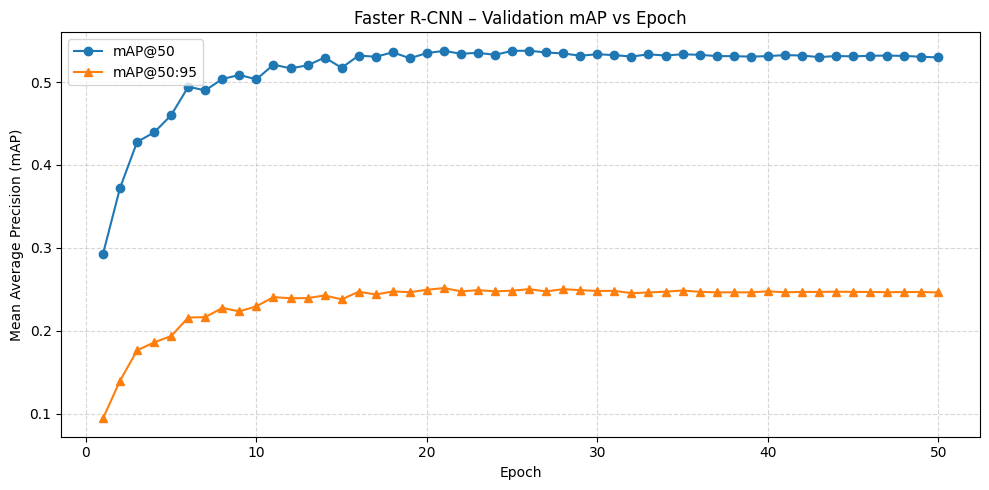

In [100]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    df_fasterrcnn["epoch"],
    df_fasterrcnn["val_map_50"],
    label="mAP@50",
    marker="o"
)

plt.plot(
    df_fasterrcnn["epoch"],
    df_fasterrcnn["val_map"],
    label="mAP@50:95",
    marker="^"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Average Precision (mAP)")
plt.title("Faster R-CNN – Validation mAP vs Epoch")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

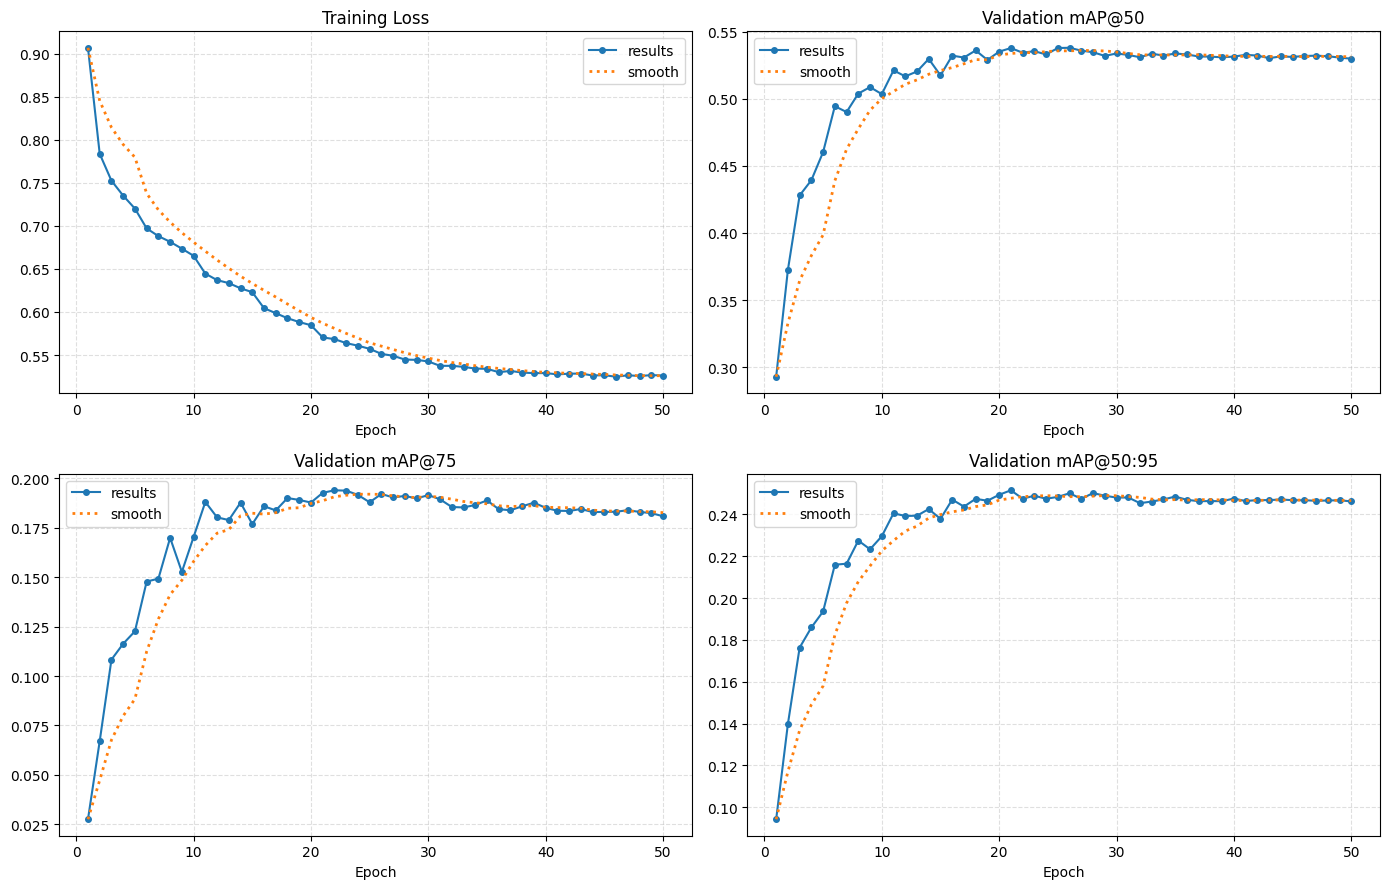

In [103]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

epochs = history["epoch"]
train_loss = history["train_loss"]
val_map = history["val_map"][::2]
val_map_50 = history["val_map_50"]
val_map_75 = history["val_map_75"]

df = pd.DataFrame({
    "epoch": epochs,
    "train_loss": train_loss,
    "val_map": val_map,
    "val_map_50": val_map_50,
    "val_map_75": val_map_75
})

window = 5
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plots = [
    ("train_loss", "Training Loss"),
    ("val_map_50", "Validation mAP@50"),
    ("val_map_75", "Validation mAP@75"),
    ("val_map", "Validation mAP@50:95")
]

for ax, (column, title) in zip(axes.flatten(), plots):
    ax.plot(
        df["epoch"], df[column],
        marker="o", markersize=4,
        linewidth=1.5, label="results"
    )
    ax.plot(
        df["epoch"],
        df[column].rolling(window=window, min_periods=1).mean(),
        linestyle=":",
        linewidth=2,
        label="smooth"
    )
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()

plt.tight_layout()
plt.show()

## Load best moodel

In [45]:
model_fasterrcnn_v1_best_50 = load_faster_rcnn_v1_base_vgg().to(device)

checkpoint_best_50 = torch.load(
    "checkpoints/fasterrcnn_v1_best.pth",
    map_location=device,
    weights_only=False
)

model_fasterrcnn_v1_best_50.load_state_dict(
    checkpoint_best_50["model_state_dict"]
)
print("Last epoch:", checkpoint_best_50["epoch"])
print("Best val mAP:", checkpoint_best_50.get("val_map", None))

Last epoch: 21
Best val mAP: 0.2515137195587158


In [115]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def show_predictions(
    images,
    evaluation,
    num_images=5,
    score_threshold=0.5
):
    predictions = evaluation["predictions"]
    targets = evaluation["targets"]
    for idx in range(min(num_images, len(predictions))):
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.imshow(images[idx].cpu().permute(1, 2, 0).numpy())
        # Ground Truth - blue
        for box, label in zip(
            targets[idx]["boxes"],
            targets[idx]["labels"]
        ):
            x1, y1, x2, y2 = box.tolist()
            ax.add_patch(patches.Rectangle(
                (x1, y1), x2-x1, y2-y1,
                linewidth=2, edgecolor="blue",
                facecolor="none"
            ))
            ax.text(x1, y1, f"GT: {label.item()} - {VOC_CLASSES[label]}", color="blue")
        # Prediction - Red
        pred = predictions[idx]
        keep = pred["scores"] >= score_threshold
        for box, label, score in zip(
            pred["boxes"][keep],
            pred["labels"][keep],
            pred["scores"][keep]
        ):
            x1, y1, x2, y2 = box.tolist()
            ax.add_patch(patches.Rectangle(
                (x1, y1), x2-x1, y2-y1,
                linewidth=2, edgecolor="red",
                facecolor="none"
            ))
            score = score.cpu()
            ax.text(x1, y2, f"Pred: {label.item()}-{VOC_CLASSES[label]} ({score:.2f})", color="red")
        ax.set_title(f"Image {idx + 1}")
        ax.axis("off")
        plt.show()

## Evaluate test set

In [61]:
test_metrics = evaluate_model(
    model=model_fasterrcnn_v1_best_50,
    data_loader=test_loader,
    device=device
)

test_map = test_metrics["map"]
test_map_50 = test_metrics["map_50"]
test_map_75 = test_metrics["map_75"]

test_map = test_metrics["map"]
print(f"Test mAP: {test_map:.4f} | mAP@50: {test_map_50:.4f} | mAP@75: {test_map_75:.4f}")

mAP@0.5: 0.5098 | mAP@0.75: 0.1814 | mAP@0.5:0.95: 0.2393 | Precision@0.5: 0.7175 | Recall@0.5: 0.4517
Test mAP: 0.2393 | mAP@50: 0.5098 | mAP@75: 0.1814


In [105]:
test_metrics

{'map_50': 0.5098392367362976,
 'map_75': 0.18142542243003845,
 'map': 0.2392713874578476,
 'precision': 0.7175,
 'recall': 0.45173137460650575,
 'predictions': [{'boxes': tensor([[148.1737,  63.6798, 253.2813, 258.3011],
           [ 66.2830, 143.1423, 354.0000, 412.8407],
           [ 40.1672, 194.5980, 218.6930, 427.2824],
           [118.8650, 141.4218, 237.3373, 431.1414],
           [ 77.5900,  90.3797, 316.2970, 301.7025],
           [110.6801, 141.8457, 342.7386, 399.3282],
           [183.1176,  75.0996, 263.4527, 185.1190]]),
   'labels': tensor([15, 13, 13, 13, 15, 12, 15]),
   'scores': tensor([0.9983, 0.8438, 0.4902, 0.3047, 0.1655, 0.0658, 0.0547])},
  {'boxes': tensor([[149.7995,  59.8270, 327.5534, 296.1668],
           [159.4786, 155.7224, 355.3315, 270.3940],
           [137.9940,  41.0786, 344.2844, 290.5238],
           [112.9851,  35.5573, 349.8634, 257.4119],
           [150.3406, 139.5344, 302.8951, 272.7345],
           [ 63.1314,   0.0000, 449.3899, 324.0000]])

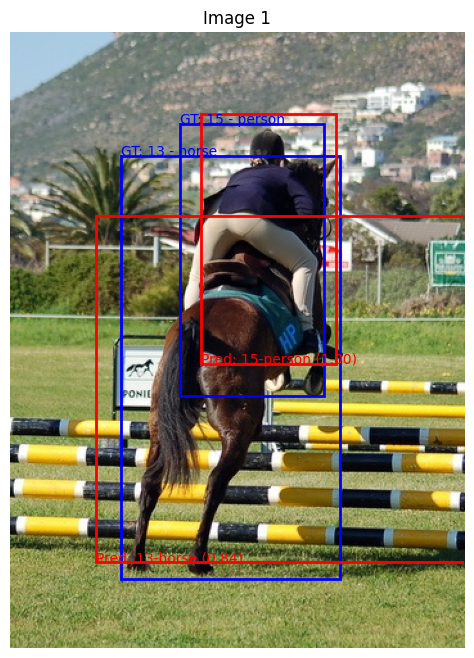

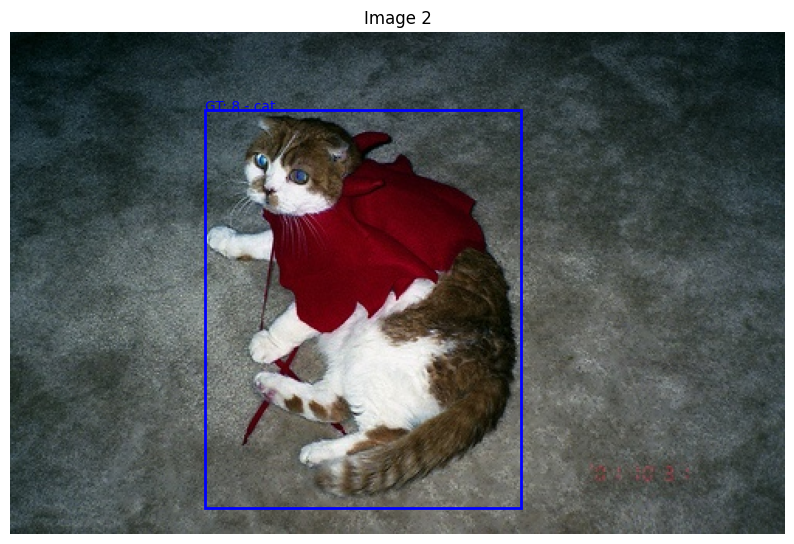

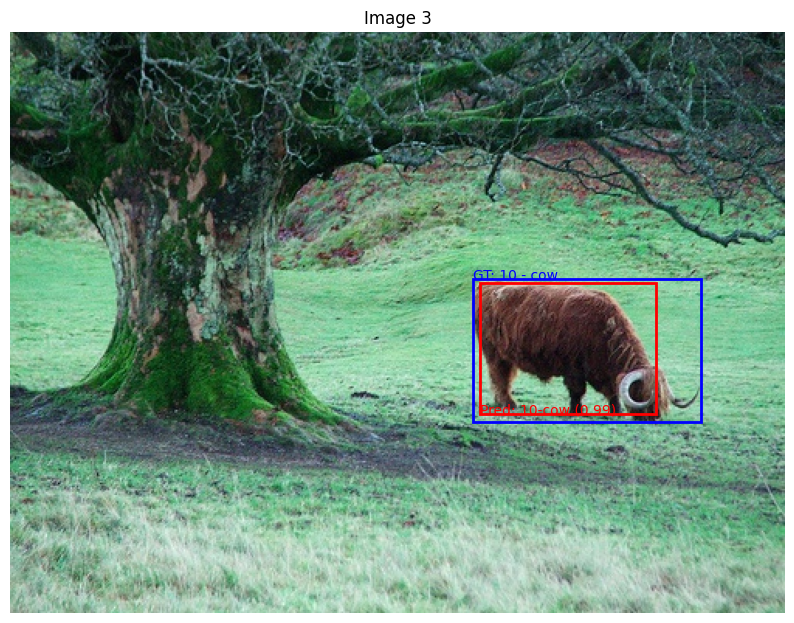

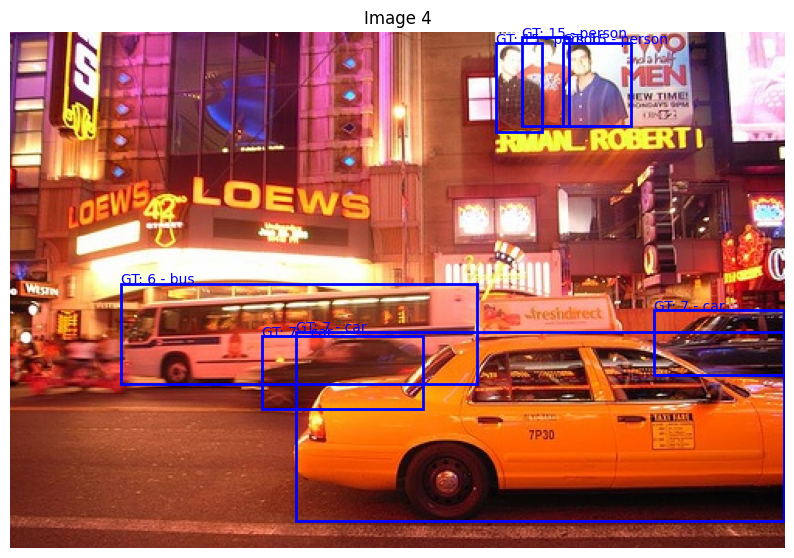

In [116]:
images, _ = next(iter(test_loader))

show_predictions(
    images,
    test_metrics,
    num_images=4,
    score_threshold=0.8
)